# Notebook 11: Constrained Portfolio Optimization and Robustness

**Project:** Factor Investing and Portfolio Optimization in Indian Markets  
**Universe:** Reliance, TCS, Infosys, HDFC Bank, ICICI Bank  
**Data period:** 2020–2025  
**Purpose:** Examine whether optimized portfolio weights remain sensible when we change practical constraints and estimation assumptions.

## Research questions

1. How do position limits affect minimum-variance and maximum-Sharpe portfolios?
2. How sensitive are optimized weights to the assumed risk-free rate?
3. How do shrinkage covariance estimates compare with the sample covariance matrix?
4. Do conclusions change when expected returns are estimated from a shorter training window?
5. How concentrated are the resulting portfolios?

### Methodological guardrails

- The portfolio universe remains small and fixed at five stocks.
- All fitting and optimization use training data only.
- Results are evaluated on a later test period.
- Portfolios are long-only and fully invested.
- These are historical experiments, not forecasts or investment recommendations.

## 1. Setup

In [11]:
# If needed in Colab, uncomment:
# %pip install -q yfinance scipy scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from IPython.display import display

SEED = 42
TRADING_DAYS = 252
START_DATE = "2020-01-01"
END_DATE = "2026-01-01"  # exclusive
TRAIN_END = "2023-12-31"
TEST_START = "2024-01-01"
RISK_FREE_RATE = 0.06

TICKERS = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]
ASSET_NAMES = {
    "RELIANCE.NS": "Reliance",
    "TCS.NS": "TCS",
    "INFY.NS": "Infosys",
    "HDFCBANK.NS": "HDFC Bank",
    "ICICIBANK.NS": "ICICI Bank",
}
np.random.seed(SEED)
print("Configuration loaded.")

Configuration loaded.


## 2. Download and prepare price data

Prices are downloaded with `auto_adjust=True`, which adjusts the price series for splits and dividends. We keep complete observations across all five stocks.

In [12]:
raw = yf.download(
    TICKERS, start=START_DATE, end=END_DATE,
    auto_adjust=True, progress=False, group_by="column", threads=True
)
if raw.empty:
    raise RuntimeError("No market data returned. Check connection and ticker symbols.")

if isinstance(raw.columns, pd.MultiIndex):
    if "Close" in raw.columns.get_level_values(0):
        prices = raw["Close"].copy()
    elif "Close" in raw.columns.get_level_values(1):
        prices = raw.xs("Close", axis=1, level=1).copy()
    else:
        raise KeyError("Close prices not found in downloaded data.")
else:
    raise ValueError("Expected multiple ticker columns, but received a single-level price table.")

missing = [t for t in TICKERS if t not in prices.columns]
if missing:
    raise ValueError(f"Missing tickers: {missing}")

prices = prices[TICKERS].sort_index().dropna(how="any")
prices = prices.loc[~prices.index.duplicated(keep="first")]
returns = prices.pct_change().replace([np.inf, -np.inf], np.nan).dropna()
returns = returns.rename(columns=ASSET_NAMES)

train_returns = returns.loc[:TRAIN_END].copy()
test_returns = returns.loc[TEST_START:].copy()

if len(train_returns) < 252 or test_returns.empty:
    raise ValueError("Insufficient training or test data. Check the date range.")

print(f"Training: {train_returns.index.min().date()} to {train_returns.index.max().date()} ({len(train_returns)} observations)")
print(f"Test: {test_returns.index.min().date()} to {test_returns.index.max().date()} ({len(test_returns)} observations)")
display(prices.head())

Training: 2020-01-02 to 2023-12-29 (991 observations)
Test: 2024-01-01 to 2025-12-31 (495 observations)


Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,672.216187,1821.426758,619.740356,595.677246,514.797852
2020-01-02,683.660278,1813.065796,617.932068,599.474121,518.490479
2020-01-03,684.484070,1849.198608,627.436157,590.925232,516.812012
2020-01-06,668.609314,1849.031006,621.422424,578.136719,504.199860
2020-01-07,678.895752,1853.568237,612.212830,587.291260,501.514343


## 3. Baseline estimates

Annualized mean returns and covariance are estimated using the training sample only.

In [13]:
mu_full = train_returns.mean() * TRADING_DAYS
cov_sample_daily = train_returns.cov()
cov_sample = cov_sample_daily * TRADING_DAYS

cov_lw_daily = LedoitWolf().fit(train_returns.values).covariance_
cov_lw = pd.DataFrame(cov_lw_daily * TRADING_DAYS,
                      index=train_returns.columns, columns=train_returns.columns)

display(pd.DataFrame({
    "Annualized Mean Return": mu_full,
    "Sample Volatility": np.sqrt(np.diag(cov_sample)),
    "Shrinkage Volatility": np.sqrt(np.diag(cov_lw)),
}).style.format("{:.2%}"))

,Annualized Mean Return,Sample Volatility,Shrinkage Volatility
Ticker,,,
Reliance,21.17%,31.20%,31.12%
TCS,19.42%,25.23%,25.41%
Infosys,25.32%,28.97%,28.98%
HDFC Bank,12.10%,28.36%,28.40%
ICICI Bank,21.97%,33.93%,33.76%


## 4. Optimization functions and constraints

For portfolio weights \(w\), the variance is $$w^\top \Sigma w$$. We impose:
- fully invested: $$\sum_i w_i = 1$$
- long-only: $$w_i \geq 0$$
- optional upper bound $$w_i \leq c,$$ where \(c\) is the maximum position size.

The maximum-Sharpe objective uses the selected annual risk-free-rate assumption.

In [14]:
ASSETS = list(train_returns.columns)
N = len(ASSETS)

def portfolio_vol(weights, cov):
    variance = float(weights @ cov.values @ weights)
    return np.sqrt(max(variance, 0.0))

def portfolio_sharpe(weights, mu, cov, risk_free_rate=RISK_FREE_RATE):
    vol = portfolio_vol(weights, cov)
    if vol <= 1e-12:
        return np.nan
    return (float(weights @ mu.values) - risk_free_rate) / vol

def optimize_portfolio(mu, cov, objective="min_variance", max_weight=1.0,
                       risk_free_rate=RISK_FREE_RATE):
    if max_weight < 1.0 / N or max_weight > 1.0:
        raise ValueError(f"max_weight must be between {1/N:.3f} and 1.0.")

    bounds = tuple((0.0, max_weight) for _ in range(N))
    constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1.0},)
    x0 = np.repeat(1 / N, N)

    if objective == "min_variance":
        fun = lambda w: float(w @ cov.values @ w)
    elif objective == "max_sharpe":
        fun = lambda w: -portfolio_sharpe(w, mu, cov, risk_free_rate)
    else:
        raise ValueError("objective must be 'min_variance' or 'max_sharpe'.")

    result = minimize(fun, x0=x0, method="SLSQP", bounds=bounds,
                      constraints=constraints,
                      options={"maxiter": 2000, "ftol": 1e-12})
    if not result.success:
        raise RuntimeError(f"{objective} optimization failed: {result.message}")
    weights = np.clip(result.x, 0, max_weight)
    weights = weights / weights.sum()
    return pd.Series(weights, index=ASSETS)

def weight_concentration(weights):
    w = np.asarray(weights, dtype=float)
    return {
        "Largest Weight": np.max(w),
        "Effective Number of Assets": 1.0 / np.sum(w**2),
        "Herfindahl Index": np.sum(w**2),
    }
print("Optimization functions defined.")

Optimization functions defined.


## 5. Position-limit sensitivity

Compare minimum-variance and maximum-Sharpe weights under different per-stock position caps. The 20% cap corresponds to equal weights in this five-stock universe, so it is included as a boundary reference.

,Reliance,TCS,Infosys,HDFC Bank,ICICI Bank
Min Variance | cap=20%,20.00%,20.00%,20.00%,20.00%,20.00%
Max Sharpe | cap=20%,20.00%,20.00%,20.00%,20.00%,20.00%
Min Variance | cap=25%,21.50%,25.00%,22.24%,25.00%,6.26%
Max Sharpe | cap=25%,25.00%,25.00%,25.00%,0.00%,25.00%
Min Variance | cap=35%,17.88%,35.00%,13.89%,30.94%,2.29%
Max Sharpe | cap=35%,23.61%,22.10%,35.00%,0.00%,19.30%
Min Variance | cap=50%,16.12%,44.58%,7.50%,29.77%,2.02%
Max Sharpe | cap=50%,22.46%,10.25%,50.00%,0.00%,17.29%
Min Variance | cap=100%,16.12%,44.58%,7.50%,29.77%,2.02%
Max Sharpe | cap=100%,21.99%,4.95%,56.61%,0.00%,16.46%


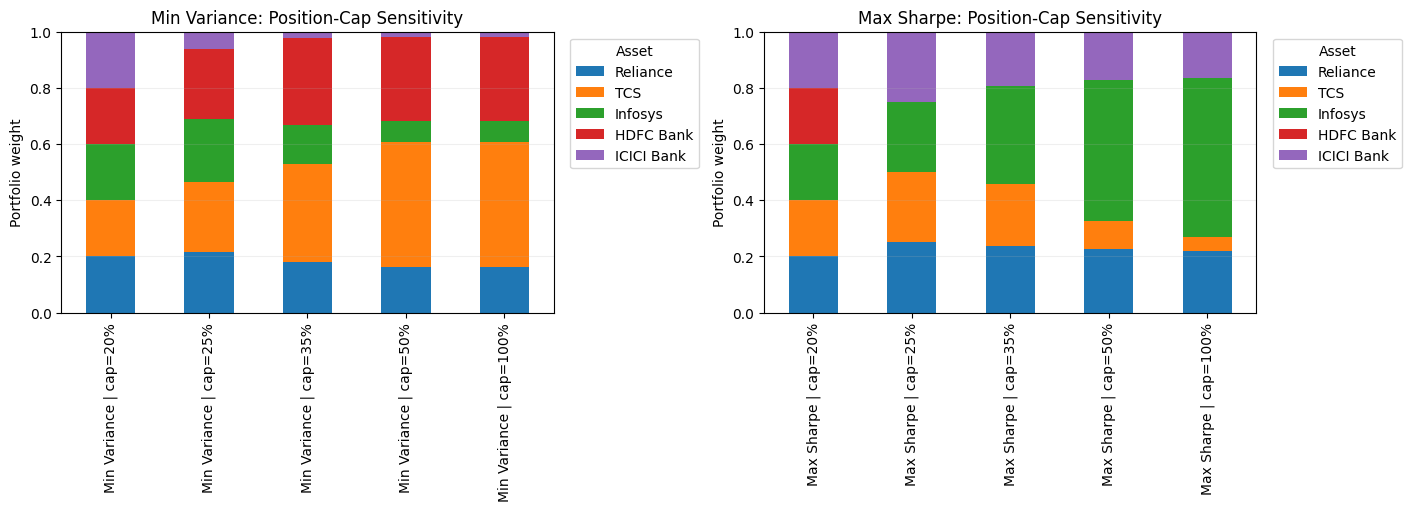

In [15]:
caps = [0.20, 0.25, 0.35, 0.50, 1.00]
weight_scenarios = {}

for cap in caps:
    for method in ["min_variance", "max_sharpe"]:
        label = f"{method.replace('_', ' ').title()} | cap={cap:.0%}"
        weight_scenarios[label] = optimize_portfolio(
            mu_full, cov_sample, objective=method, max_weight=cap
        )

weight_sensitivity = pd.DataFrame(weight_scenarios).T
display(weight_sensitivity.style.format("{:.2%}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for method, ax in zip(["Min Variance", "Max Sharpe"], axes):
    subset = weight_sensitivity.loc[[idx for idx in weight_sensitivity.index if idx.startswith(method)]]
    subset.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{method}: Position-Cap Sensitivity")
    ax.set_ylabel("Portfolio weight")
    ax.set_ylim(0, 1)
    ax.legend(title="Asset", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.grid(axis="y", alpha=0.2)
plt.show()

## 6. Risk-free-rate sensitivity

The risk-free rate affects the maximum-Sharpe objective but does not directly enter the minimum-variance objective. We vary the annual assumption to see whether the selected maximum-Sharpe allocation changes.

In [16]:
rf_scenarios = [0.03, 0.05, 0.06, 0.07, 0.08]
rf_weights = {}
for rf in rf_scenarios:
    rf_weights[f"RF={rf:.0%}"] = optimize_portfolio(
        mu_full, cov_sample, objective="max_sharpe",
        max_weight=1.0, risk_free_rate=rf
    )
rf_weight_table = pd.DataFrame(rf_weights).T
display(rf_weight_table.style.format("{:.2%}"))

rf_concentration = pd.DataFrame({
    label: weight_concentration(weights)
    for label, weights in rf_weights.items()
}).T
display(rf_concentration.style.format("{:.3f}"))

,Reliance,TCS,Infosys,HDFC Bank,ICICI Bank
RF=3%,22.09%,12.36%,49.01%,0.00%,16.54%
RF=5%,22.03%,7.73%,53.76%,0.00%,16.49%
RF=6%,21.99%,4.95%,56.61%,0.00%,16.46%
RF=7%,21.94%,1.76%,59.87%,0.00%,16.43%
RF=8%,21.55%,0.00%,62.20%,0.00%,16.24%


,Largest Weight,Effective Number of Assets,Herfindahl Index
RF=3%,0.490,3.015,0.332
RF=5%,0.538,2.698,0.371
RF=6%,0.566,2.511,0.398
RF=7%,0.599,2.305,0.434
RF=8%,0.622,2.175,0.460


## 7. Sample covariance versus shrinkage covariance

Sample covariance estimates can be noisy. Ledoit-Wolf shrinkage pulls the estimated covariance toward a structured target, which can improve stability in some settings. Here we compare optimized weights from both covariance estimates while keeping the expected-return estimates and training period unchanged.

In [17]:
covariance_scenarios = {
    "Sample covariance": cov_sample,
    "Ledoit-Wolf shrinkage": cov_lw,
}
covariance_weights = {}
for cov_name, cov in covariance_scenarios.items():
    covariance_weights[f"{cov_name} | Min Variance"] = optimize_portfolio(
        mu_full, cov, objective="min_variance", max_weight=0.50
    )
    covariance_weights[f"{cov_name} | Max Sharpe"] = optimize_portfolio(
        mu_full, cov, objective="max_sharpe", max_weight=0.50
    )

covariance_weight_table = pd.DataFrame(covariance_weights).T
display(covariance_weight_table.style.format("{:.2%}"))

weight_differences = pd.DataFrame({
    "Absolute Weight Difference": (
        covariance_weight_table.loc["Sample covariance | Min Variance"]
        - covariance_weight_table.loc["Ledoit-Wolf shrinkage | Min Variance"]
    ).abs()
}).T
display(weight_differences.style.format("{:.2%}"))

,Reliance,TCS,Infosys,HDFC Bank,ICICI Bank
Sample covariance | Min Variance,16.12%,44.58%,7.50%,29.77%,2.02%
Sample covariance | Max Sharpe,22.46%,10.25%,50.00%,0.00%,17.29%
Ledoit-Wolf shrinkage | Min Variance,16.65%,41.66%,9.85%,28.53%,3.31%
Ledoit-Wolf shrinkage | Max Sharpe,22.12%,10.50%,50.00%,0.00%,17.37%


,Reliance,TCS,Infosys,HDFC Bank,ICICI Bank
Absolute Weight Difference,0.52%,2.92%,2.35%,1.24%,1.29%


## 8. Expected-return window sensitivity

Expected returns are notoriously noisy. We compare full training-period estimates with estimates based on the most recent 252 trading observations in the training sample. The covariance estimate is held fixed here so that this experiment isolates the impact of the expected-return window.

In [18]:
mu_recent = train_returns.tail(TRADING_DAYS).mean() * TRADING_DAYS
mean_window_weights = {
    "Full training | Max Sharpe": optimize_portfolio(
        mu_full, cov_sample, objective="max_sharpe", max_weight=0.50
    ),
    "Recent 252 days | Max Sharpe": optimize_portfolio(
        mu_recent, cov_sample, objective="max_sharpe", max_weight=0.50
    ),
    "Full training | Min Variance": optimize_portfolio(
        mu_full, cov_sample, objective="min_variance", max_weight=0.50
    ),
    "Recent 252 days | Min Variance": optimize_portfolio(
        mu_recent, cov_sample, objective="min_variance", max_weight=0.50
    ),
}
mean_window_table = pd.DataFrame(mean_window_weights).T
display(mean_window_table.style.format("{:.2%}"))

,Reliance,TCS,Infosys,HDFC Bank,ICICI Bank
Full training | Max Sharpe,22.46%,10.25%,50.00%,0.00%,17.29%
Recent 252 days | Max Sharpe,14.02%,50.00%,0.00%,0.00%,35.98%
Full training | Min Variance,16.12%,44.58%,7.50%,29.77%,2.02%
Recent 252 days | Min Variance,16.12%,44.58%,7.50%,29.77%,2.02%


## 9. Out-of-sample evaluation of constraint scenarios

We evaluate the cap scenarios using the test period. The weights are estimated using training data only. For clarity, this is a fixed-weight daily-return approximation, with no transaction costs or periodic rebalancing.

In [19]:
test_portfolio_returns = {}
for label, weights in weight_scenarios.items():
    test_portfolio_returns[label] = test_returns[ASSETS].to_numpy() @ weights.values

test_portfolio_returns = pd.DataFrame(test_portfolio_returns, index=test_returns.index)

def metrics(series, risk_free_rate=RISK_FREE_RATE):
    r = pd.Series(series).dropna()
    if r.empty:
        return {"Observations": 0, "Cumulative Return": np.nan,
                "Annualized Return": np.nan, "Annualized Volatility": np.nan,
                "Sharpe Ratio": np.nan, "Maximum Drawdown": np.nan}
    growth = (1 + r).cumprod()
    years = len(r) / TRADING_DAYS
    cum = growth.iloc[-1] - 1
    ann_ret = growth.iloc[-1] ** (1 / years) - 1 if growth.iloc[-1] > 0 else np.nan
    ann_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ((r.mean() * TRADING_DAYS) - risk_free_rate) / ann_vol if ann_vol > 0 else np.nan
    dd = growth / growth.cummax() - 1
    return {"Observations": len(r), "Cumulative Return": cum,
            "Annualized Return": ann_ret, "Annualized Volatility": ann_vol,
            "Sharpe Ratio": sharpe, "Maximum Drawdown": dd.min()}

oos_metrics = pd.DataFrame({col: metrics(test_portfolio_returns[col])
                            for col in test_portfolio_returns.columns}).T
display(oos_metrics.style.format({
    "Cumulative Return": "{:.2%}", "Annualized Return": "{:.2%}",
    "Annualized Volatility": "{:.2%}", "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}", "Observations": "{:.0f}",
}))

,Observations,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Min Variance | cap=20%,495,17.35%,8.49%,13.92%,0.224,-15.22%
Max Sharpe | cap=20%,495,17.35%,8.49%,13.92%,0.224,-15.22%
Min Variance | cap=25%,495,13.32%,6.58%,14.38%,0.097,-17.00%
Max Sharpe | cap=25%,495,16.03%,7.86%,15.04%,0.179,-18.54%
Min Variance | cap=35%,495,9.87%,4.91%,14.32%,-0.013,-16.90%
Max Sharpe | cap=35%,495,15.21%,7.47%,15.77%,0.155,-20.40%
Min Variance | cap=50%,495,7.09%,3.55%,14.45%,-0.102,-17.27%
Max Sharpe | cap=50%,495,17.56%,8.58%,16.75%,0.217,-21.33%
Min Variance | cap=100%,495,7.09%,3.55%,14.45%,-0.102,-17.27%
Max Sharpe | cap=100%,495,18.60%,9.07%,17.28%,0.241,-21.73%


## 10. Out-of-sample comparison plot

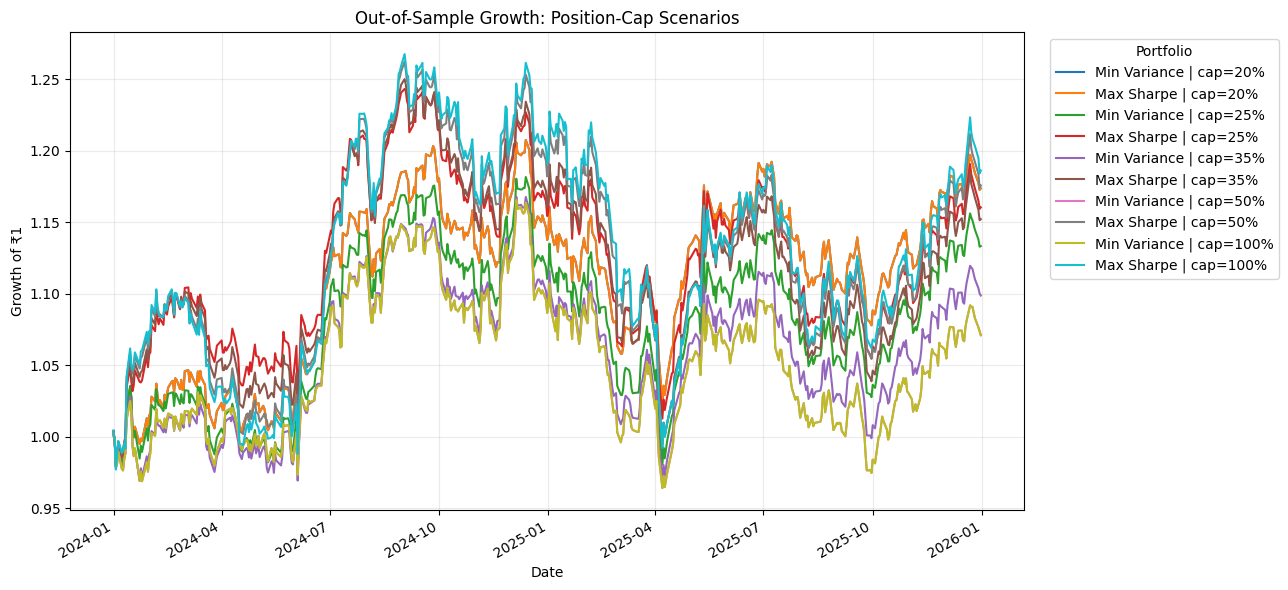

In [20]:
growth = (1 + test_portfolio_returns).cumprod()
fig, ax = plt.subplots(figsize=(13, 6))
growth.plot(ax=ax)
ax.set_title("Out-of-Sample Growth: Position-Cap Scenarios")
ax.set_ylabel("Growth of ₹1")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend(title="Portfolio", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 11. Interpretation prompts

After running the notebook, use the tables and charts to answer:

1. Which portfolios hit their position caps?
2. How much do the optimized weights change as the cap is relaxed?
3. Does the risk-free-rate assumption materially change maximum-Sharpe weights?
4. Does Ledoit-Wolf shrinkage make the minimum-variance portfolio more or less concentrated?
5. How sensitive is the maximum-Sharpe portfolio to the expected-return estimation window?
6. Which cap scenario offers a reasonable balance of return, volatility, and concentration out of sample?

Interpret the results as evidence about this specific universe and sample, not a guarantee of future performance.

## 12. Limitations and conclusion

### Limitations
- Five stocks provide a narrow and sector-concentrated investment universe.
- Historical expected returns are noisy, and maximum-Sharpe weights can react sharply to small changes in inputs.
- Position limits and risk-free-rate values are assumptions rather than universally correct settings.
- The test-period implementation does not include transaction costs, taxes, slippage, or periodic rebalancing.
- A single train/test split does not establish that the findings are robust across market regimes.

### Conclusion
This notebook investigates the stability of constrained portfolio optimization under different position caps, risk-free rates, covariance estimators, and expected-return windows. The key objective is to understand how assumptions influence weights and out-of-sample results, rather than selecting a portfolio solely because it performs best in one historical sample.